## Aquire Incident Data in 2023

In [1]:
import pandas as pd
from sodapy import Socrata

# Unauthenticated client only works with public data sets. Note 'None'
# in place of application token, and no username or password:
#client = Socrata("data.transportation.gov", None)

client = Socrata( "data.transportation.gov",
                     '1hCte9vYL7IpE7pFTGR1cbn8y',
                     username="hugo.baca4515@coyote.csusb.edu",
                     password="Hugobacaalex1!" )

# First 2000 results, returned as JSON from API / converted to Python list of
# dictionaries by sodapy.
results = client.get_all("7wn6-i5b9", year='2023')

# Convert to pandas DataFrame
Raw_Data_2023 = pd.DataFrame.from_records(results)

#let's see what we get back
print(Raw_Data_2023)


     railroadcode                        railroadname  year incidentnumber  \
0             ARR         Alaska Railroad Corporation  2023        2023086   
1             ARR         Alaska Railroad Corporation  2023        2023111   
2            BNSF                BNSF Railway Company  2023      CA0223201   
3             FEC  Florida East Coast Railway Company  2023      X31071323   
4             FEC  Florida East Coast Railway Company  2023      X32072623   
...           ...                                 ...   ...            ...   
1363          CSX                  CSX Transportation  2023      000212582   
1364          CSX                  CSX Transportation  2023      000212837   
1365          CSX                  CSX Transportation  2023      000212120   
1366          CSX                  CSX Transportation  2023      000212966   
1367           UP      Union Pacific Railroad Company  2023      0123RM025   

     incidentyear incidentmonth maintenancerailroadcode  \
0   

### Chekout labels we have to work with 

In [2]:
from numpy.core.fromnumeric import sort

column_headers = list(Raw_Data_2023.columns.values)

column_headers.sort()

print("The Column Headers:")
for header in column_headers:
  print(header)

The Column Headers:
ampm
cityname
countycode
countyname
crossingilluminated
crossingusersinjured
crossinguserskilled
crossingwarning
crossingwarningcode
crossingwarningexpanded1
crossingwarningexpanded2
crossingwarningexpanded3
crossingwarningexpanded4
crossingwarningexpanded5
crossingwarningexpanded6
crossingwarningexpanded7
crossingwarningexpandedcode1
crossingwarningexpandedcode2
crossingwarningexpandedcode3
crossingwarningexpandedcode4
crossingwarningexpandedcode5
crossingwarningexpandedcode6
crossingwarningexpandedcode7
crossingwarningexplanation
crossingwarningexplanationcode
crossingwarninglocation
crossingwarninglocationcode
date
day
district
drivercondition
driverconditioncode
driverinvehicle
driverpassedvehicle
employeesinjured
employeeskilled
equipmentinvolved
equipmentinvolvedcode
equipmentstruck
equipmentstruckcode
equipmenttype
equipmenttypecode
estimatedrecordedspeedcode
estimatedvehiclespeed
form54filed
gradecrossingid
hazmatinvolvement
hazmatinvolvementcode
hazmatrelea

### Set up Labels & Dictionary Search

In [3]:
from numpy import NaN
dictionary_data_raw = pd.read_excel('../Data_Dictionaries/Form_54_Data_Dictionary.xlsx')

dictionary = pd.DataFrame.from_records(dictionary_data_raw)

dictionary.columns.values

dictionary = dictionary.filter(items=['Display Name', 'Description'])

print(dictionary)

                Display Name  \
0    Reporting Railroad Code   
1    Reporting Railroad Name   
2                       Year   
3            Accident Number   
4                   PDF Link   
..                       ...   
168                      NaN   
169                      NaN   
170                      NaN   
171                      NaN   
172                      NaN   

                                           Description  
0    Code of the reporting railroad [Block #1a on F...  
1    Name of the reporting railroad [Block #1 on Fo...  
2                                         Report year   
3    Assigned accident number for the reporting rai...  
4                                     PDF link to form  
..                                                 ...  
168                                                NaN  
169                                                NaN  
170                                                NaN  
171                                          

### Search for Descriptions

name_to_descriptions = ['']

In [4]:
# Create a dictionary to store the corresponding names and descriptions
name_to_description = {}
for index, row in dictionary.iterrows():
    name_to_description[row['Display Name']] = row['Description']

# Get the description for the variable 'report year'
description = name_to_description['Year']
print(description)

#Personal Prefence: Allows me to quickly pull descriptions for variable.

Report year 


Verify data is from only 2023

In [5]:
#i would like to break up data into smaller chunks to make it easier to work with
# such as by 10 years

print(Raw_Data_2023['year'].max())
print(Raw_Data_2023['year'].min())




2023
2023


Peak at data in table form

In [6]:

from tabulate import tabulate
print(tabulate(Raw_Data_2023, headers = 'keys', tablefmt = 'psql'))


+------+----------------+------------------------------------------------------------+--------+------------------+----------------+-----------------+---------------------------+------------------------------------------------------------+--------------------------------+---------------------------+----------------------------+-------------------+-------------------------+---------+-------+--------+----------+--------+----------+----------------------+----------------------+--------------+---------------------+-------------+----------------+----------------------+----------------------+---------------------+-----------------+-------------------+---------------------+-------------------------+------------------------+--------------------+---------------------------+--------------------------------+-------------------------+------------------------+---------------------------+-----------------------+---------------------------------------+-------------------------+---------------------+--

## Data Clean Up

In [7]:
#Explore for NA's, missing data, and redunnacy

isnaValues = Raw_Data_2023.isna()
print(isnaValues)

# Check for NA values
missing_values = Raw_Data_2023.isna().sum()

#check for null values
missing_data = Raw_Data_2023.isnull().sum()
print(missing_data)

# Check for missing data
for column in Raw_Data_2023.columns:
    if missing_values[column] > 0:
        print(f"The column {column} has {missing_values[column]} missing values.")

# Check for redundancy
for column in Raw_Data_2023.columns:
    if Raw_Data_2023[column].duplicated().sum() > 0:
        print(f"The column {column} has {Raw_Data_2023[column].duplicated().sum()} duplicate values.")

#lets try to clean up raw data

# Calculate the percentage of missing values in each column
missing_values = Raw_Data_2023.isna().mean()

# Drop columns with more than 30% missing values
drop_list = [column for column in missing_values.index if missing_values[column] > 0.3]

# Drop the columns
Clean_Data_2023 = Raw_Data_2023.drop(columns=drop_list)


      railroadcode  railroadname   year  incidentnumber  incidentyear  \
0            False         False  False           False         False   
1            False         False  False           False         False   
2            False         False  False           False         False   
3            False         False  False           False         False   
4            False         False  False           False         False   
...            ...           ...    ...             ...           ...   
1363         False         False  False           False         False   
1364         False         False  False           False         False   
1365         False         False  False           False         False   
1366         False         False  False           False         False   
1367         False         False  False           False         False   

      incidentmonth  maintenancerailroadcode  maintenancerailroadname  \
0             False                    False      

What changed?

In [8]:
# Check the shape of the raw data
print(f"The Raw Data Frame has {Raw_Data_2023.shape[0]} rows and {Raw_Data_2023.shape[1]} columns.")
print(f"The clean data freame has a mean of missing: {missing_values}")
print(f"\n The Raw Data Frame has {len(Raw_Data_2023.columns)} labels.")
print(f"\n The Clean Data Frame now has {len(Clean_Data_2023.columns)} labels.")
print("\n Count of labels dropped: \n", len(Raw_Data_2023.columns) - len(Clean_Data_2023.columns) )
print("\n Deleted Labels: \n", drop_list)
print("\n Cleaned Data Labels: \n", Clean_Data_2023.columns.values)

The Raw Data Frame has 1368 rows and 147 columns.
The clean data freame has a mean of missing: railroadcode                      0.000000
railroadname                      0.000000
year                              0.000000
incidentnumber                    0.000000
incidentyear                      0.000000
                                    ...   
other_parent_railroad_name        0.997807
other_railroad_holding_company    0.997807
other_railroad_grouping           0.998538
other_railroad_class              0.998538
other_railroad_smt_grouping       0.998538
Length: 147, dtype: float64

 The Raw Data Frame has 147 labels.

 The Clean Data Frame now has 115 labels.

 Count of labels dropped: 
 32

 Deleted Labels: 
 ['reporting_railroad_company_grouping', 'maintenance_railroad_grouping', 'crossingwarningexpandedcode3', 'crossingwarningexpanded3', 'crossingwarningcode', 'crossingwarning', 'crossingwarningexplanationcode', 'crossingwarningexplanation', 'crossingwarningexpandedcode4', '

#### Remove labels that will not be used

In [9]:
Raw_Data_2023.columns = Raw_Data_2023.columns.str.strip()


In [10]:
columns_to_drop = [
    'railroadcode', 'maintenancerailroadcode', 'maintenancerailroadname',
    'neareststation', 'subdivision', 'reporting_parent_railroad_code',
    'maintenance_parent_railroad_name', 'maintenance_railroad_holding_company',
    'url', 'maintenance_parent_railroad_code', 'maintenance_railroad_smt_grouping',
    'reporting_railroad_holding_company', 'reporting_railroad_smt_grouping',
    'reporting_parent_railroad_name'
]

columns_to_drop = [col for col in columns_to_drop if col in Clean_Data_2023.columns]

Clean_Data_2023.drop(columns=columns_to_drop, inplace=True)


### Assess that there is no label with more than 30% na 

In [11]:
missing_values_clean = Clean_Data_2023.isna().mean()


In [12]:
print(missing_values_clean)

railroadname                  0.000000
year                          0.000000
incidentnumber                0.000000
incidentyear                  0.000000
incidentmonth                 0.000000
                                ...   
totalinjuredform55a           0.000000
district                      0.000000
reportkey                     0.000000
reporting_railroad_class      0.146199
maintenance_railroad_class    0.078947
Length: 101, dtype: float64


### Exlporing our clean data

COOK                32
HARRIS              26
LOS ANGELES         23
BROWARD             19
FULTON              19
SHELBY              17
JEFFERSON           16
PALM BEACH          15
MARION              14
MONTGOMERY          13
WAYNE               12
JACKSON             11
MARICOPA            10
MIAMI-DADE          10
ALAMEDA              9
BUTLER               9
POLK                 9
SUFFOLK              9
ALLEN                9
EAST BATON ROUGE     8
Name: countyname, dtype: int64


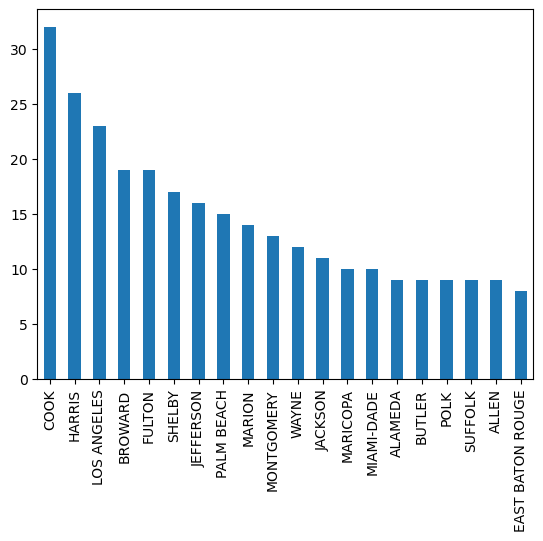

In [13]:
#lets see which county experiences the most accidents
# so basically get a graph x = county, y = number of accidents, all rows in this set are accidents
#get indivial counties and keep track of how many times they appear
import matplotlib.pyplot as plt
import numpy as np
incidentsbycounties = Clean_Data_2023['countyname'].value_counts()
#get the top 10 counties
incidentsbycounties = incidentsbycounties[:20,]

#save to file
np.savez('../2023incidentsbycounties.npz', incidentsbycounties.to_numpy())
print(incidentsbycounties)

#plot the data
incidentsbycounties.plot.bar()
plt.show()


Quantity of unique counties: 570
+-----+---------------------+---------------------+
|     | countyname          |   totalkilledform57 |
|-----+---------------------+---------------------|
|   0 | ADA                 |                   1 |
|   1 | ADAIR               |                   1 |
|   2 | ADAMS               |                   1 |
|   3 | AIKEN               |                   0 |
|   4 | ALAMEDA             |                   1 |
|   5 | ALLEGAN             |                   1 |
|   6 | ALLEGHENY           |                   0 |
|   7 | ALLEN               |                   0 |
|   8 | ARKANSAS            |                   0 |
|   9 | AROOSTOOK           |                   0 |
|  10 | ASCENSION           |                   0 |
|  11 | ASHTABULA           |                   0 |
|  12 | ATASCOSA            |                   0 |
|  13 | AUSTIN              |                   0 |
|  14 | AUTAUGA             |                   0 |
|  15 | BACA                |  

<Figure size 1400x700 with 0 Axes>

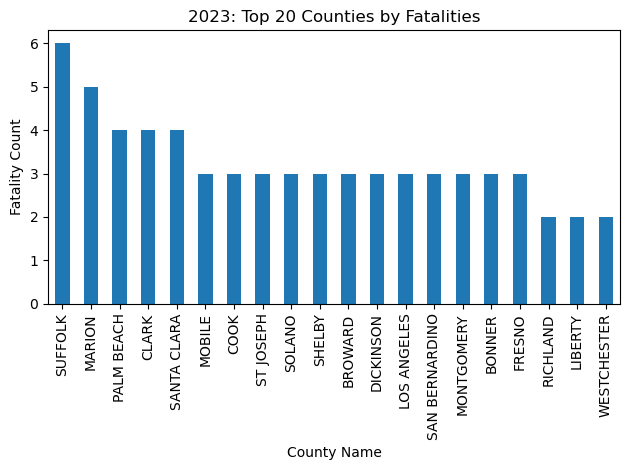

In [14]:
import matplotlib.pyplot as plt
from tabulate import tabulate

# 1. Calculate the number of unique counties
county_count = Clean_Data_2023['countyname'].nunique()
print("Quantity of unique counties:", county_count)
Clean_Data_2023['totalkilledform57'] = pd.to_numeric(Clean_Data_2023['totalkilledform57'], errors='coerce')

# 2. Sum of 'totalkilledform57' grouped by 'countyname'
result_df = Clean_Data_2023.groupby('countyname')['totalkilledform57'].sum().reset_index()
print(tabulate(result_df, headers='keys', tablefmt='psql'))

# 3. Plot top 20 counties by fatalities
top20countiesbyfatalities = result_df.sort_values(by='totalkilledform57', ascending=False).head(20)

plt.figure(figsize=(14, 7))
top20countiesbyfatalities.plot.bar(x='countyname', y='totalkilledform57', legend=False)
plt.title('2023: Top 20 Counties by Fatalities')
plt.xlabel(str('County Name'))
plt.ylabel('Fatality Count')
plt.tight_layout()
plt.show()

#save to file
np.savez('../2023top20countiesbyfatalities.npz', top20countiesbyfatalities.to_numpy())

025422P    4
050330S    3
631785D    3
725759B    3
637728K    3
718062K    3
676300G    3
025430G    3
153762C    2
723692P    2
510017L    2
916933L    2
028442L    2
819330X    2
628146G    2
766163B    2
348506D    2
053938J    2
272640A    2
524223P    2
Name: gradecrossingid, dtype: int64


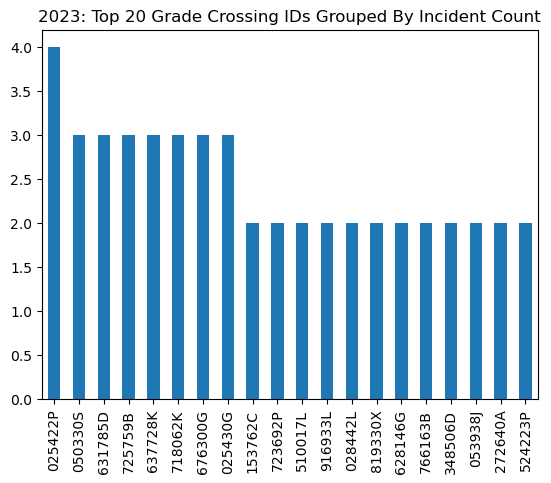

   countyname gradecrossingid  count
0         ADA         819330X      2
1         ADA         819326H      1
2       ADAIR         330391G      1
3       ADAIR         330625H      1
4       ADAMS         070779Y      1
5       ADAMS         072813K      1
6       ADAMS         083178C      1
7       ADAMS         804419H      1
8       ADAMS         804434K      1
9       AIKEN         715767R      1
10    ALAMEDA         749712Y      2
11    ALAMEDA         749634U      1
12    ALAMEDA         749709R      1
13    ALAMEDA         749728V      1
14    ALAMEDA         749774W      1
15    ALAMEDA         751041C      1
16    ALAMEDA         751154H      1
17    ALAMEDA         834232U      1
18    ALLEGAN         234677M      1
19    ALLEGAN         234707C      1


In [15]:
GCF = Clean_Data_2023['gradecrossingid'].value_counts()
print(GCF.head(20))

GCF = GCF[:20,]
GCF.plot.bar(x='index', y='count', title='2023: Top 20 Grade Crossing IDs Grouped By Incident Count')
plt.show()
np.savez('../2023top20GradeCrossingFrequency.npz', GCF.to_numpy())

GCFbycounty = Clean_Data_2023.groupby('countyname')['gradecrossingid'].value_counts().reset_index(name='count')
print(GCFbycounty.head(20))



In [16]:
topcorssingid = Clean_Data_2023[Clean_Data_2023['gradecrossingid'] == '025422P'].get(['countyname', 'statename'])
print(topcorssingid)


    countyname statename
787   MARICOPA   ARIZONA
796   MARICOPA   ARIZONA
798   MARICOPA   ARIZONA
803   MARICOPA   ARIZONA


In [17]:
len(Clean_Data_2023['gradecrossingid'].unique())

1306

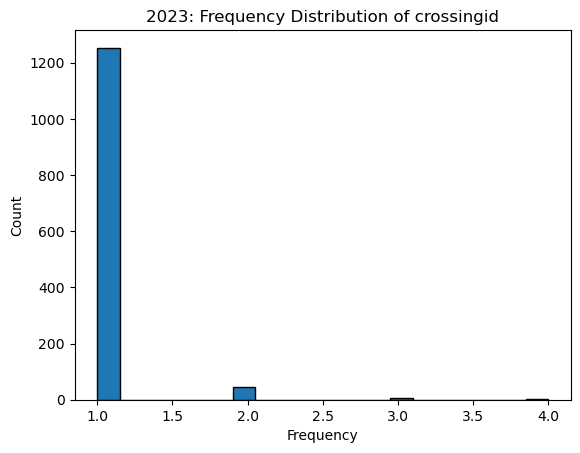

In [18]:
# Assuming you have a DataFrame named df with a 'crossingid' column
# Use value_counts() to get the frequency of each unique crossingid
crossingid_frequency = Clean_Data_2023['gradecrossingid'].value_counts()
#
np.savez('../2023crossingid_frequency.npz', crossingid_frequency.to_numpy() )
# Plot a histogram of the frequencies
plt.hist(crossingid_frequency, bins=20, edgecolor='k')
plt.xlabel('Frequency')
plt.ylabel('Count')
plt.title('2023: Frequency Distribution of crossingid')
plt.show()

/var/folders/8s/cfwx8yqs1h7921qxk7ssn8sm0000gn/T/ipykernel_2117/2479405366.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(crossingid_frequency, kde=True)


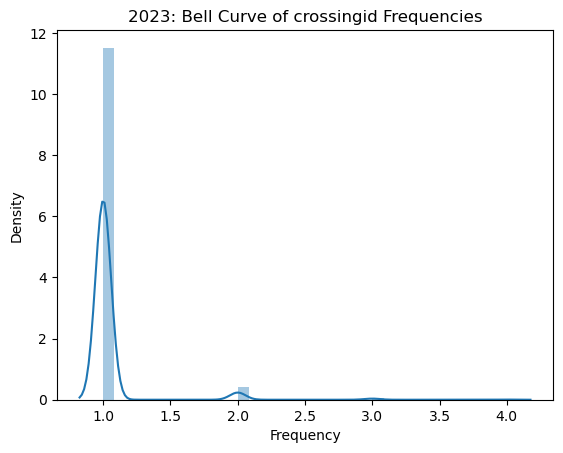

In [19]:
import seaborn as sns

# Assuming you have a DataFrame named df with a 'crossingid' column
# Use value_counts() to get the frequency of each unique crossingid
crossingid_frequency = Clean_Data_2023['gradecrossingid'].value_counts()

# Create a bell curve (normal distribution) plot
sns.distplot(crossingid_frequency, kde=True)
plt.xlabel('Frequency')
plt.ylabel('Density')
plt.title('2023: Bell Curve of crossingid Frequencies')
plt.show()

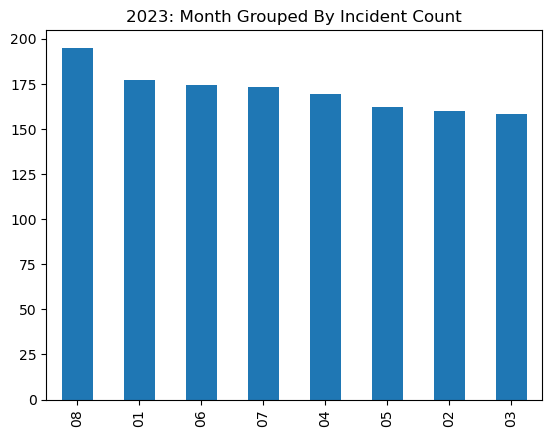

In [20]:
month_frequency = Clean_Data_2023['incidentmonth'].value_counts()

month_frequency.plot.bar(x='index', y='count', title='2023: Month Grouped By Incident Count')
plt.show()

### Histogram for each column in the Clean_Data_2023
create a histogram for each column in the Clean_Data_2023 DataFrame, showing only the top 12 most frequent values if there are more than 12 unique values, or all if there are less than 12. 

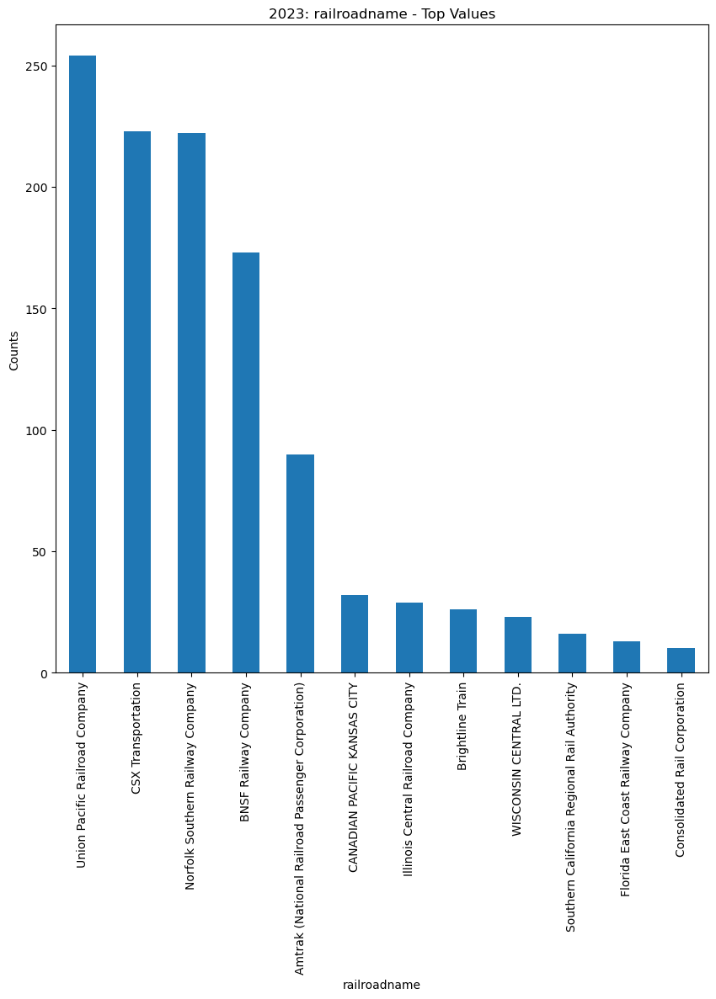

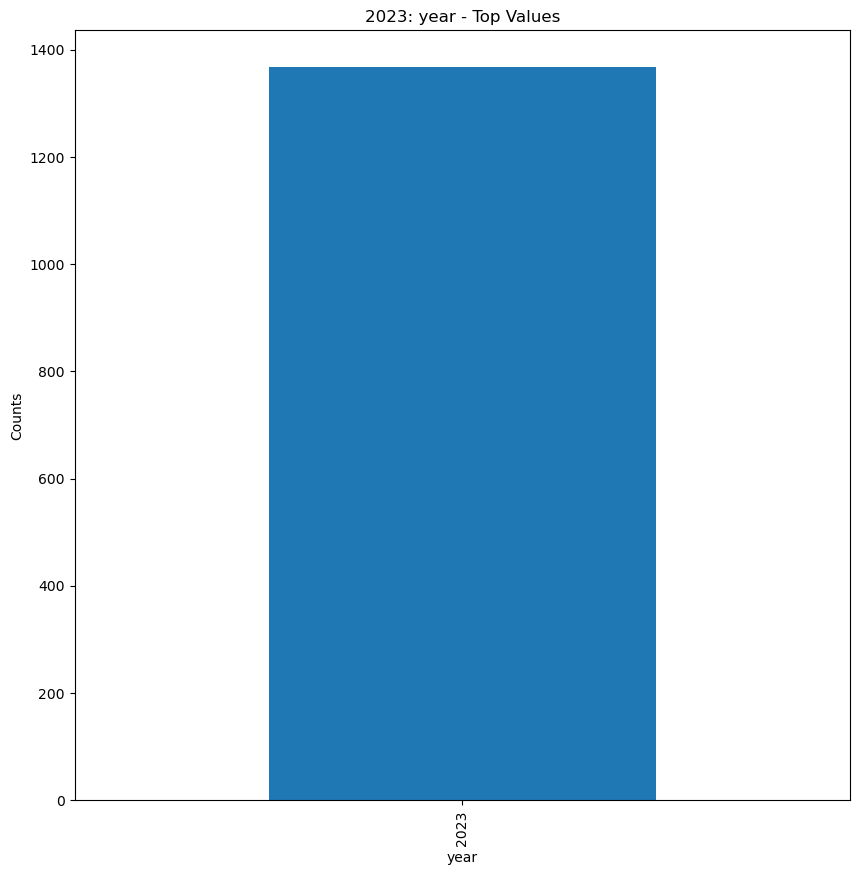

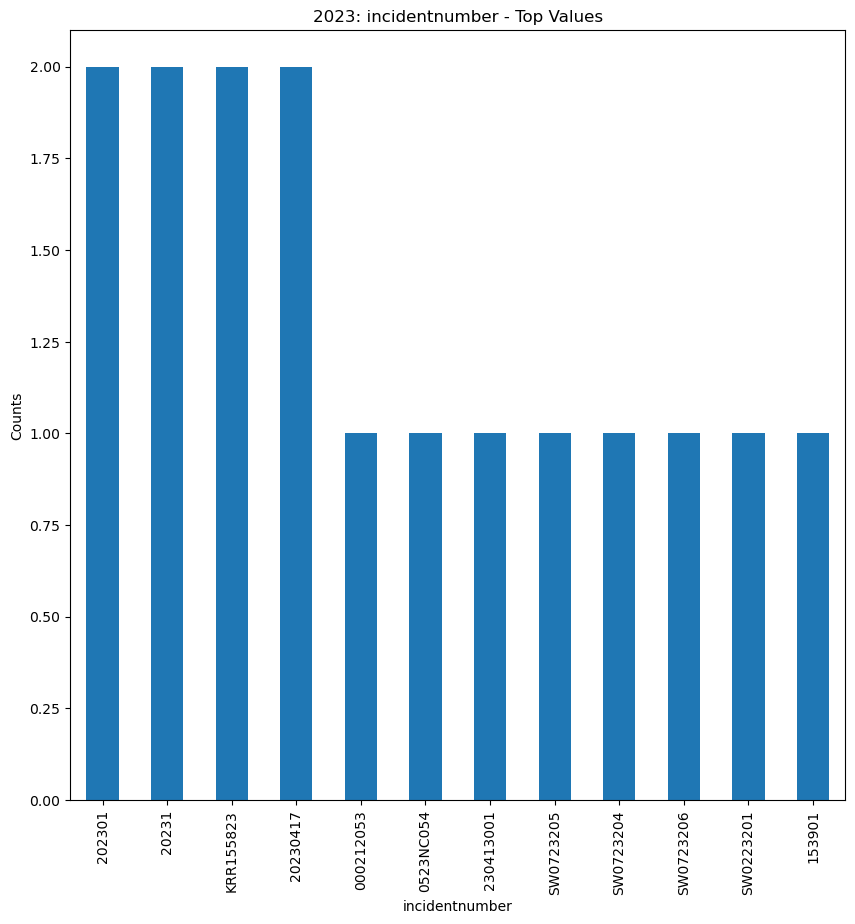

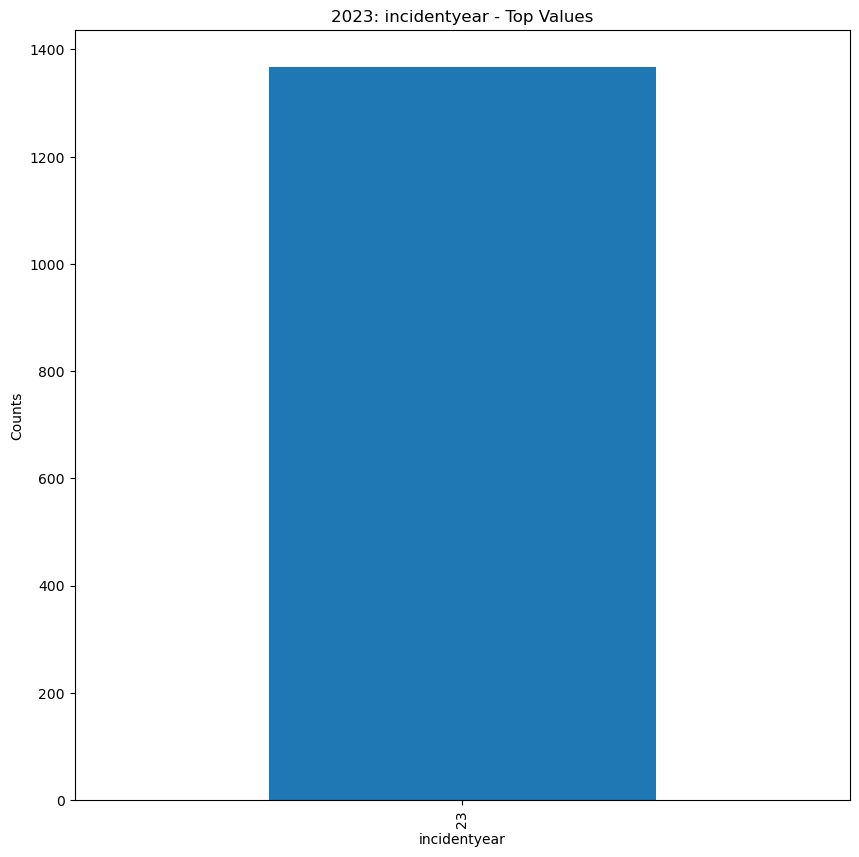

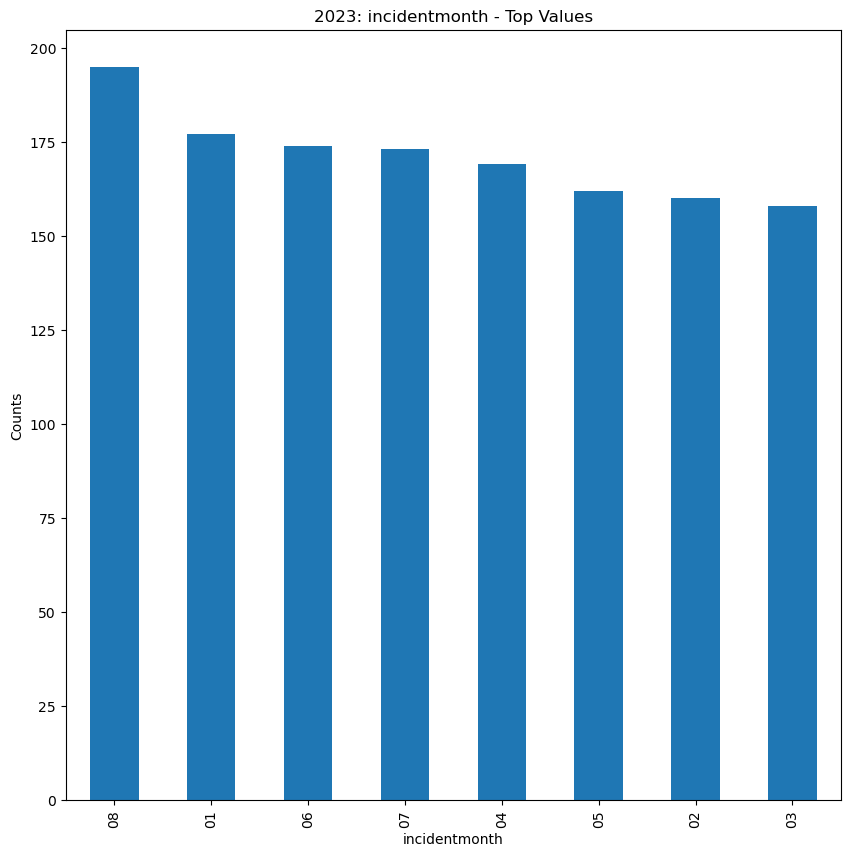

...

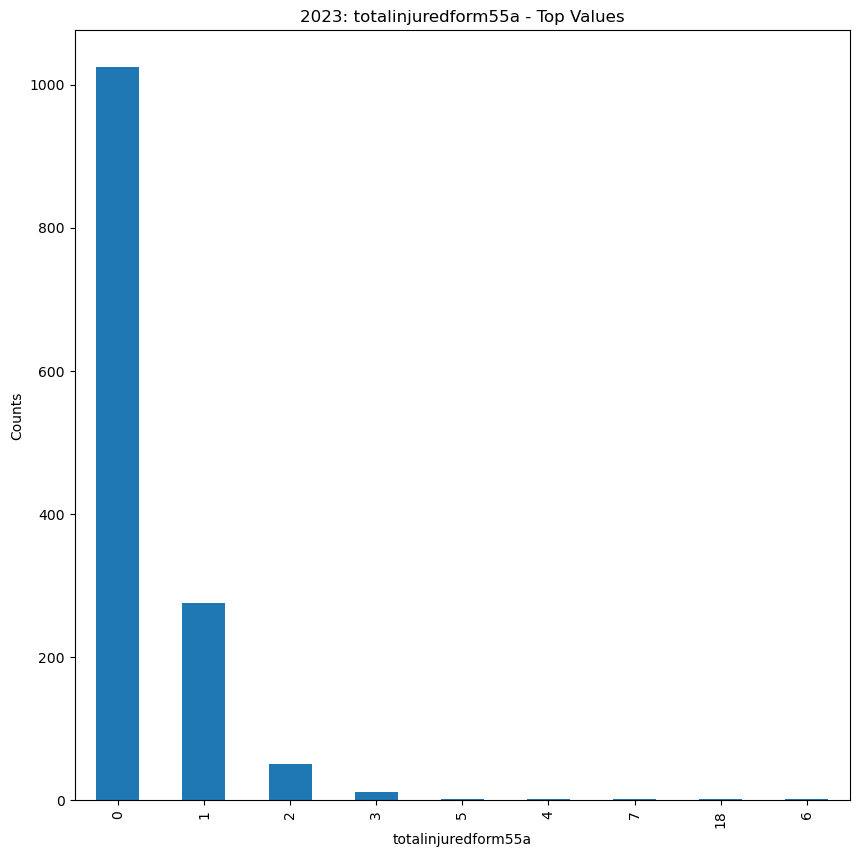

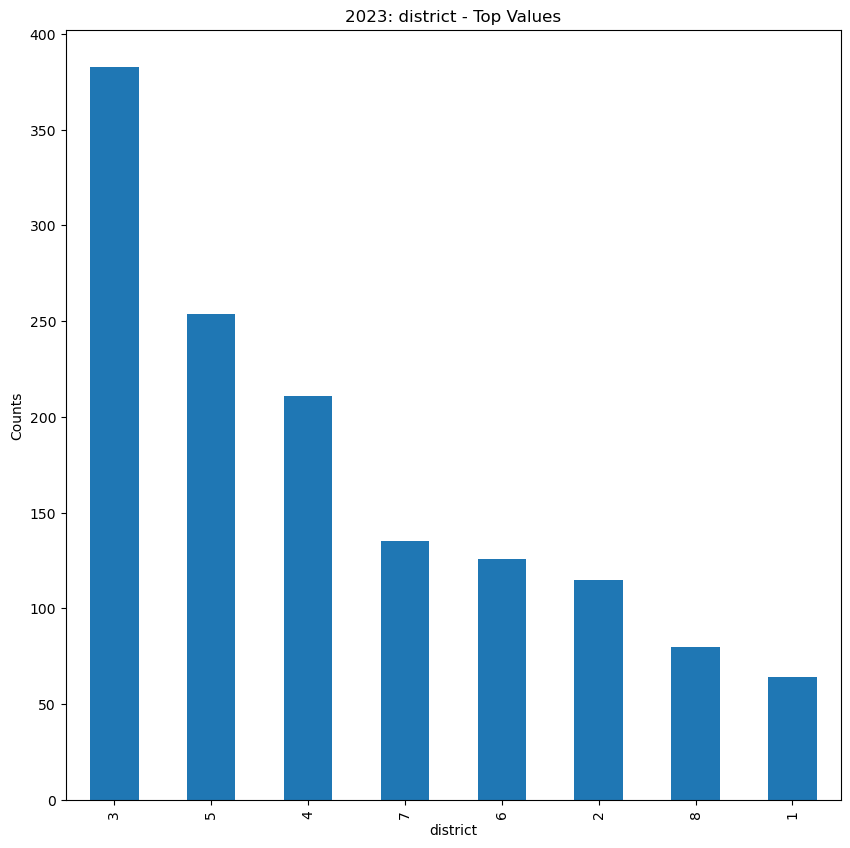

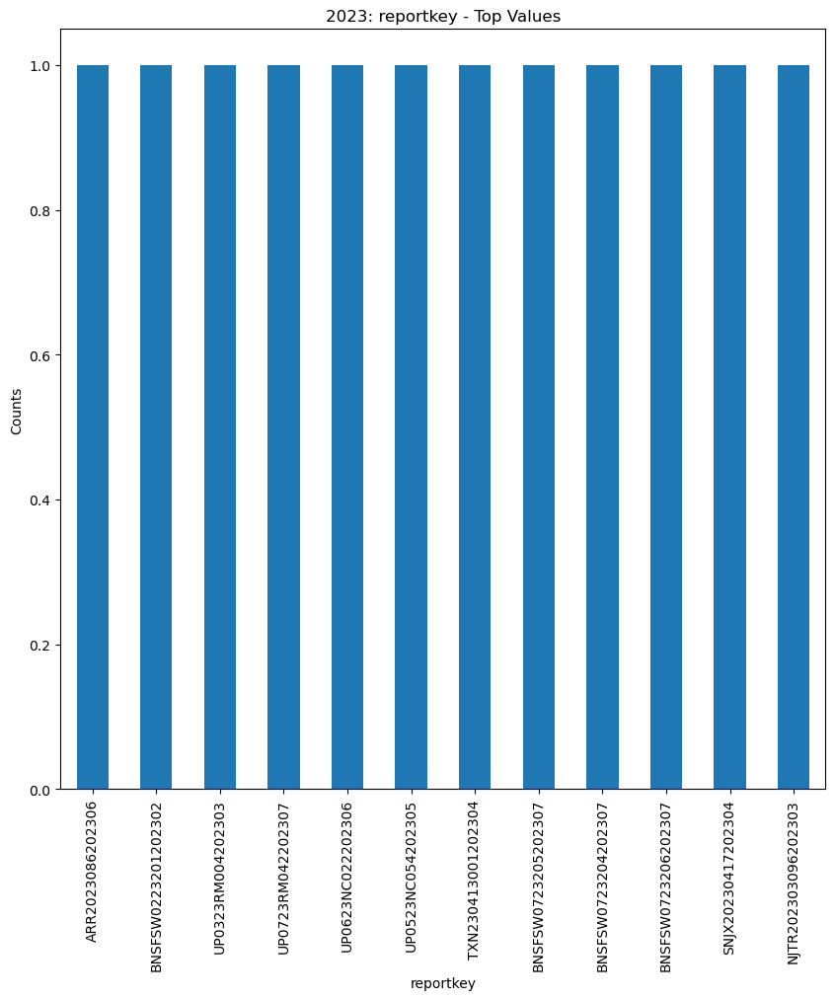

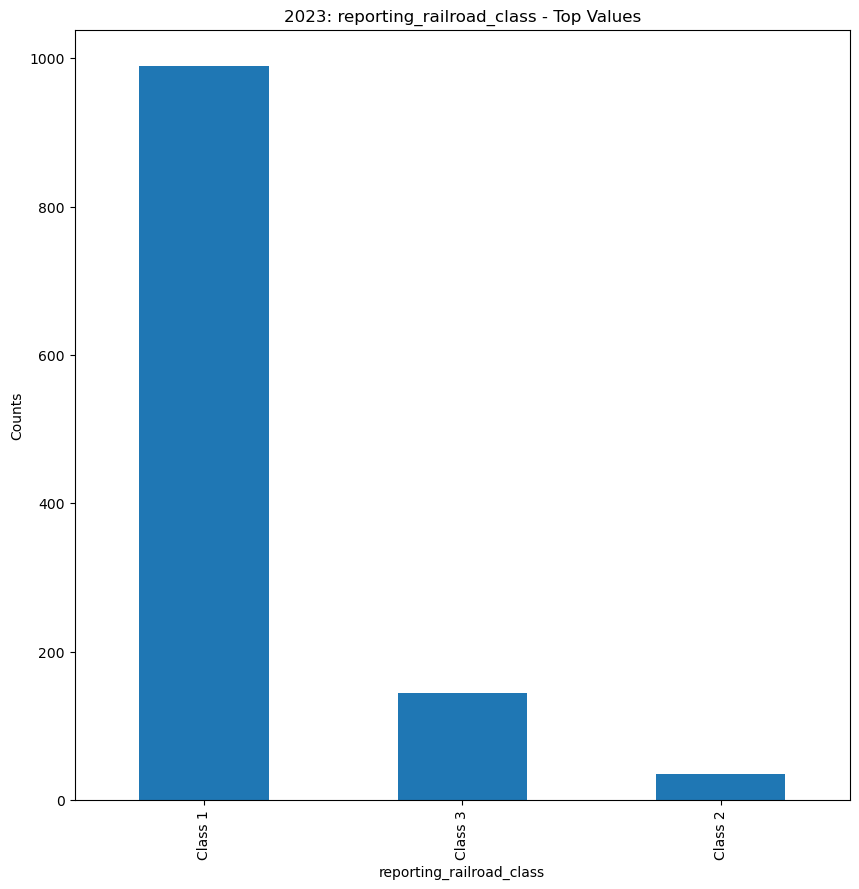

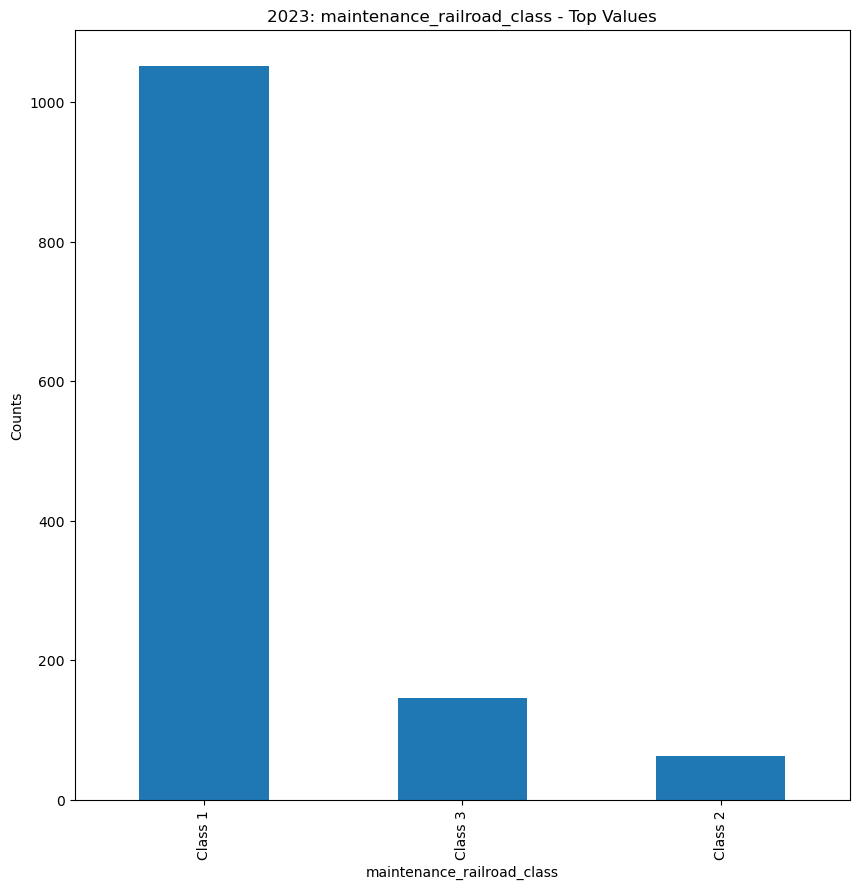

In [21]:
import matplotlib.pyplot as plt

# Iterate over each column in the DataFrame
for column in Clean_Data_2023.columns:
    # Calculate the value counts of the current column
    value_counts = Clean_Data_2023[column].value_counts()

    # Determine the number of unique values
    unique_values = len(value_counts)

    # If there are more than 12 unique values, select the top 12
    if unique_values > 12:
        value_counts = value_counts.head(12)

    # Create a new figure and axis for the histogram
    plt.figure(figsize=(10, 10))

    # Plot the bar chart
    value_counts.plot.bar(title=f'2023: {column} - Top Values')

    # Label the axes
    plt.xlabel(column)
    plt.ylabel('Counts')
    
    # Save the plot to a PNG file
    filename = f'2023_{column} Top Dozen Values.png'
    plt.savefig('../Plots_Graphs/Incident_Graphs/' + filename)

    # Show the plot
    plt.show()



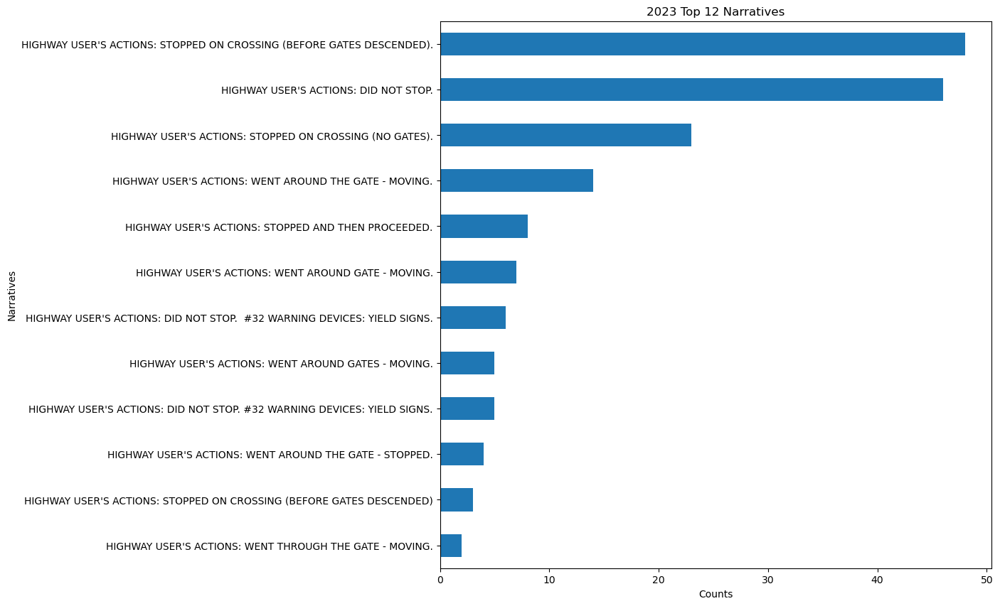

In [22]:


# Get the top occurrences in the 'narrative' column
topnarrative = Clean_Data_2023['narrative'].value_counts().head(12)

# Create a horizontal bar chart
plt.figure(figsize=(10, 10))  #  adjust the figure size as needed

# Plot the bar chart with horizontal orientation
topnarrative.plot.barh(title='2023 Top 12 Narratives')

# Invert the y-axis to have the highest count at the top
plt.gca().invert_yaxis()

# Label the axes
plt.xlabel('Counts')
plt.ylabel('Narratives')

#save fig 
plt.savefig('2023_Top 12 Narratives', bbox_inches = 'tight')

# Show the plot
plt.show()



## Thesis
What leads to fatailites and injuries?, so Y - fatalitities or injuries, X - all other labels

Now that we understand our conditions for an incident, lets gather all the inventory data on the invidual crossings from form 71. 

Gather incident crossing id's

In [23]:
np.savez('../Data/Internal/processed/2023form54ids.npz', Clean_Data_2023['gradecrossingid'].to_numpy())

Let's gather how many id's we have so we know what to expect out of form 71 query

In [24]:
distinct_values = Clean_Data_2023['gradecrossingid'].unique()
sum_distinct_values = len(distinct_values)
sum_distinct_values

1306

Saving Clean Data frame

In [25]:
np.savez('../Data/Internal/processed/2023IncidentDataClean.npz', Clean_Data_2023.to_numpy())

Gather Report Keys: to be used in querying form 55 ops data

In [26]:
np.save('../Data/Internal/processed/2023form54ReportKeys.npz', Clean_Data_2023['reportkey'].to_numpy())

## Assess Data Needs for Qual & Quant


I also want qualitative data and quantitative Data Sets
Consider what we need to endcode and create new feature engineered data sets


### Crossing ID Data Frame

In [27]:
print(tabulate(Clean_Data_2023, headers = 'keys', tablefmt = 'psql'))

def check_column_types(Clean_Data_2023):
    for column in Clean_Data_2023.columns:
        unique_types = set(Clean_Data_2023[column].apply(type))
        print(f"Column '{column}' has types: {unique_types}")

check_column_types(Clean_Data_2023)


+------+------------------------------------------------------------+--------+------------------+----------------+-----------------+--------------------------------+---------------------------+----------------------------+-------------------+-------------------------+---------+-------+--------+----------+--------+----------+--------------+---------------------+-------------+----------------+----------------------+----------------------+---------------------+-----------------+-------------------+---------------------+-------------------------+------------------------+--------------------+---------------------------+--------------------------------+-------------------------+------------------------+---------------------------+-----------------------+---------------------------------------+-------------------------+---------------------+------------------------+--------------------+---------------+------------------+--------------+------------------------+--------------------+------------

In [28]:
def check_column_types(Clean_Data_2023):
    type_counter = {}  # Initialize an empty dictionary to store type counts

    for column in Clean_Data_2023.columns:
        # Get unique types for each column
        unique_types = set(Clean_Data_2023[column].apply(type))


        # Count each type
        for dtype in unique_types:
            if dtype in type_counter:
                type_counter[dtype] += 1
            else:
                type_counter[dtype] = 1

    # Print the total counts for each type
    print("\nType Counts Across All Columns:")
    for dtype, count in type_counter.items():
        print(f"{dtype}: {count}")

# Call the function with your DataFrame
check_column_types(Clean_Data_2023)



Type Counts Across All Columns:
<class 'str'>: 100
<class 'float'>: 57
<class 'int'>: 1


In [29]:
categorical_cols = Clean_Data_2023.select_dtypes(include=['object', 'category']).columns
quantitative_cols = Clean_Data_2023.select_dtypes(include=['int64', 'float64']).columns


In [30]:
print(f"Categorical columns: {categorical_cols}")

Categorical columns: Index(['railroadname', 'year', 'incidentnumber', 'incidentyear',
       'incidentmonth', 'maintainenanceincidentnumber',
       'maintenanceincidentyear', 'maintenanceincidentmonth',
       'gradecrossingid', 'date', 'month', 'day', 'hour', 'minute', 'ampm',
       'time', 'countycode', 'countyname', 'statecode', 'statename',
       'cityname', 'highwayname', 'publicprivatecode', 'publicprivate',
       'highwayusercode', 'highwayuser', 'estimatedvehiclespeed',
       'vehicledirectioncode', 'vehicledirection', 'highwayuserpositioncode',
       'highwayuserposition', 'equipmentinvolvedcode', 'equipmentinvolved',
       'railroadcarunitposition', 'equipmentstruckcode', 'equipmentstruck',
       'hazmatinvolvementcode', 'hazmatinvolvement', 'hazmatreleasedbycode',
       'hazmatreleasedby', 'temperature', 'visibilitycode', 'visibility',
       'weatherconditioncode', 'weathercondition', 'equipmenttypecode',
       'equipmenttype', 'tracktypecode', 'tracktype', 'track

In [31]:
print(f"Quantitative columns: {quantitative_cols}")

Quantitative columns: Index(['totalkilledform57'], dtype='object')


### encoding

In [32]:
from sklearn.preprocessing import LabelEncoder

# Assuming Clean_Data_2023 is your original DataFrame
# Filter columns that do not contain 'code' and create a copy to avoid the SettingWithCopyWarning
Encoded_Clean_Data = Clean_Data_2023.filter(regex='^(?!.*code).*$').copy()

# Initialize a LabelEncoder
le = LabelEncoder()

# Apply LabelEncoder to each non-'code' column
for col in Encoded_Clean_Data.columns:
    # Check if the column is of a categorical type
    if Encoded_Clean_Data[col].dtype == 'object' or Encoded_Clean_Data[col].dtype.name == 'category':
        # Fit and transform the data
        # Use .loc to ensure the changes are done on the DataFrame copy
        Encoded_Clean_Data.loc[:, col] = le.fit_transform(Encoded_Clean_Data[col])

print(Encoded_Clean_Data)

      railroadname  year  incidentnumber  incidentyear  incidentmonth  \
0                3     0             962             0              5   
1                3     0             965             0              6   
2               11     0            1101             0              1   
3               44     0            1360             0              6   
4               44     0            1361             0              6   
...            ...   ...             ...           ...            ...   
1363            19     0             186             0              6   
1364            19     0             200             0              7   
1365            19     0             168             0              6   
1366            19     0             208             0              7   
1367           127     0             253             0              0   

      maintainenanceincidentnumber  maintenanceincidentyear  \
0                              856                        0 

/var/folders/8s/cfwx8yqs1h7921qxk7ssn8sm0000gn/T/ipykernel_2117/1780896229.py:16: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  Encoded_Clean_Data.loc[:, col] = le.fit_transform(Encoded_Clean_Data[col])
/var/folders/8s/cfwx8yqs1h7921qxk7ssn8sm0000gn/T/ipykernel_2117/1780896229.py:16: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  Encoded_Clean_Data.loc[:, col] = le.fit_transform(Encoded_Clean_Data[col])
/var/folders/8s/cfwx8yqs1h7921qxk7ssn8sm0000gn/T/ipykernel_2117/1780896229.py:16: DeprecationWarning: In a future version, `df.iloc[:, i] = 

In [33]:
Encoded_Clean_Data.head()

,railroadname,year,incidentnumber,incidentyear,incidentmonth,maintainenanceincidentnumber,maintenanceincidentyear,maintenanceincidentmonth,gradecrossingid,date,...,totalkilledform57,totalinjuredform57,railroadtype,railroadreporting,totalkilledform55a,totalinjuredform55a,district,reportkey,reporting_railroad_class,maintenance_railroad_class
0,3,0,962,0,5,856,0,5,1235,153,...,0,0,6,0,0,0,7,7,1,1
1,3,0,965,0,6,859,0,6,1250,193,...,0,0,6,0,0,0,7,8,1,1
2,11,0,1101,0,1,958,0,1,78,30,...,0,0,1,0,0,0,6,131,0,0
3,44,0,1360,0,6,1230,0,6,265,192,...,1,0,2,0,1,0,2,630,1,1
4,44,0,1361,0,6,1231,0,6,301,205,...,0,0,2,0,0,0,2,631,1,1


### remove a unneccesary labels 

In [ ]:
Encoded_Clean_Data = Encoded_Clean_Data.drop(columns=[ 'railroadname','year', 'incidentnumber', 'reportkey' ])


In [34]:
Encoded_Clean_Data.head()

,railroadname,year,incidentnumber,incidentyear,incidentmonth,maintainenanceincidentnumber,maintenanceincidentyear,maintenanceincidentmonth,gradecrossingid,date,...,totalkilledform57,totalinjuredform57,railroadtype,railroadreporting,totalkilledform55a,totalinjuredform55a,district,reportkey,reporting_railroad_class,maintenance_railroad_class
0,3,0,962,0,5,856,0,5,1235,153,...,0,0,6,0,0,0,7,7,1,1
1,3,0,965,0,6,859,0,6,1250,193,...,0,0,6,0,0,0,7,8,1,1
2,11,0,1101,0,1,958,0,1,78,30,...,0,0,1,0,0,0,6,131,0,0
3,44,0,1360,0,6,1230,0,6,265,192,...,1,0,2,0,1,0,2,630,1,1
4,44,0,1361,0,6,1231,0,6,301,205,...,0,0,2,0,0,0,2,631,1,1


In [35]:
Encoded_Clean_Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1368 entries, 0 to 1367
Data columns (total 77 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   railroadname                  1368 non-null   int64
 1   year                          1368 non-null   int64
 2   incidentnumber                1368 non-null   int64
 3   incidentyear                  1368 non-null   int64
 4   incidentmonth                 1368 non-null   int64
 5   maintainenanceincidentnumber  1368 non-null   int64
 6   maintenanceincidentyear       1368 non-null   int64
 7   maintenanceincidentmonth      1368 non-null   int64
 8   gradecrossingid               1368 non-null   int64
 9   date                          1368 non-null   int64
 10  month                         1368 non-null   int64
 11  day                           1368 non-null   int64
 12  hour                          1368 non-null   int64
 13  minute                        136

In [36]:
Encoded_Clean_Data.to_numpy()

array([[   3,    0,  962, ...,    7,    1,    1],
       [   3,    0,  965, ...,    8,    1,    1],
       [  11,    0, 1101, ...,  131,    0,    0],
       ...,
       [  19,    0,  168, ...,  545,    0,    0],
       [  19,    0,  208, ...,  585,    0,    0],
       [ 127,    0,  253, ..., 1091,    0,    0]])

In [37]:
from sklearn.preprocessing import StandardScaler

# Handling missing data (if any)
Encoded_Clean_Data.fillna(method='ffill', inplace=True)  # or df.dropna()

# Normalize/Standardize Data
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(Encoded_Clean_Data), columns=Encoded_Clean_Data.columns)

# Convert to NumPy Array
numpy_array = df_scaled.values

# Reshape if necessary (example: reshaping for a time-series model)
# numpy_array = numpy_array.reshape((numpy_array.shape[0], 1, numpy_array.shape[1]))

# Now, numpy_array is ready to be used as a tensor in various frameworks

In [38]:
numpy_array

array([[-1.25331107,  0.        ,  0.71014195, ..., -1.71305948,
         0.28451389,  0.52027775],
       [-1.25331107,  0.        ,  0.71776339, ..., -1.71052724,
         0.28451389,  0.52027775],
       [-1.08357247,  0.        ,  1.06326857, ..., -1.39906188,
        -0.59012655, -0.51272655],
       ...,
       [-0.91383388,  0.        , -1.30699859, ..., -0.35071506,
        -0.59012655, -0.51272655],
       [-0.91383388,  0.        , -1.20537942, ..., -0.24942551,
        -0.59012655, -0.51272655],
       [ 1.37763714,  0.        , -1.09105785, ...,  1.03188727,
        -0.59012655, -0.51272655]])

In [39]:
numpy_array.shape

(1368, 77)

In [42]:
# Assuming original_array is your original 2D array of shape (1368, 73)
# Reshape to a 3-mode tensor, e.g., (1368, 73, 1)

tensor_3d = numpy_array.reshape((1368, 77, 1))

#1306, 73, 1
# how to define simialrites: binary such as if in state , 0 no , 1 yes
# create many similarity matrices#
#each matric shouldbe 1306 x 1306
#use 5 or 6 matricies
# ex 1306 x 1306 x 5

# run tensor decomposition for clustering
#binary clustering : ABC , tensor X 
# send input , tensor X, rank R, 
# ouput is A size 1306 x R, B 1306 x R, C 5 x R, 
# if R is 2, use A or B for immediate clustering, 1306 x 2
# use R to infer 
# what does A mean ? Importance of crossing to latten comp, R is number of latten components, 
# what is C, important of every graph with respect to every component 
#  one example: crossing, corssing, sameroad: 0,1, where R 2= , then 
# we can check inventory data: 1306, two groups, what is similar about them,

#yield number 


# Check the new shape
print(tensor_3d.shape)  # Output: (1368, 73, 1)

(1368, 77, 1)


Create 3 mode tensor . generate similarity matrix, to capture crossings

In [43]:
np.save('../Data/Internal/processed/tensor_3d', tensor_3d)

In [44]:
from sklearn.preprocessing import LabelEncoder

# Assuming Clean_Data_2023 is your original DataFrame
# Filter the 'code' columns and create a copy to avoid the SettingWithCopyWarning
Encoded_Clean_Data_Codes = Clean_Data_2023.filter(like='code').copy()

# Initialize a LabelEncoder
le = LabelEncoder()

# Apply LabelEncoder to each 'code' column
for col in Encoded_Clean_Data_Codes.columns:
    # Fit and transform the data
    # Use .loc to ensure the changes are done on the DataFrame copy
    Encoded_Clean_Data_Codes.loc[:, col] = le.fit_transform(Encoded_Clean_Data_Codes[col])



/var/folders/8s/cfwx8yqs1h7921qxk7ssn8sm0000gn/T/ipykernel_2117/419928319.py:14: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  Encoded_Clean_Data_Codes.loc[:, col] = le.fit_transform(Encoded_Clean_Data_Codes[col])
/var/folders/8s/cfwx8yqs1h7921qxk7ssn8sm0000gn/T/ipykernel_2117/419928319.py:14: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  Encoded_Clean_Data_Codes.loc[:, col] = le.fit_transform(Encoded_Clean_Data_Codes[col])
/var/folders/8s/cfwx8yqs1h7921qxk7ssn8sm0000gn/T/ipykernel_2117/419928319.py:14: DeprecationWarning: In a future versi

In [45]:
print(Encoded_Clean_Data_Codes.head())


   countycode  statecode  publicprivatecode  highwayusercode  \
0          62          1                  1                0   
1          86          1                  1                0   
2          23          4                  1                0   
3          65          8                  1                9   
4          15          8                  0                2   

   vehicledirectioncode  highwayuserpositioncode  equipmentinvolvedcode  \
0                     1                        2                      1   
1                     1                        2                      6   
2                     0                        2                      0   
3                     1                        1                      0   
4                     3                        2                      5   

   equipmentstruckcode  hazmatinvolvementcode  hazmatreleasedbycode  ...  \
0                    1                      4                     3  ...   
1           

In [ ]:
Encoded_Clean_Data_Codes.columns.values

In [46]:
# Select columns that contain 'code'
code_columns = [col for col in Clean_Data_2023.columns if 'code' in col]

# Create a new DataFrame with only those columns
code_df = Clean_Data_2023[code_columns]
print(code_df.columns.values)
code_df.head()

['countycode' 'statecode' 'publicprivatecode' 'highwayusercode'
 'vehicledirectioncode' 'highwayuserpositioncode' 'equipmentinvolvedcode'
 'equipmentstruckcode' 'hazmatinvolvementcode' 'hazmatreleasedbycode'
 'visibilitycode' 'weatherconditioncode' 'equipmenttypecode'
 'tracktypecode' 'estimatedrecordedspeedcode' 'traindirectioncode'
 'crossingwarningexpandedcode1' 'crossingwarningexpandedcode2'
 'roadwayconditioncode' 'crossingwarninglocationcode'
 'userstruckbysecondtraincode' 'highwayuseractioncode'
 'viewobstructioncode' 'driverconditioncode']


,countycode,statecode,publicprivatecode,highwayusercode,vehicledirectioncode,highwayuserpositioncode,equipmentinvolvedcode,equipmentstruckcode,hazmatinvolvementcode,hazmatreleasedbycode,...,estimatedrecordedspeedcode,traindirectioncode,crossingwarningexpandedcode1,crossingwarningexpandedcode2,roadwayconditioncode,crossingwarninglocationcode,userstruckbysecondtraincode,highwayuseractioncode,viewobstructioncode,driverconditioncode
0,122,02,Y,A,2,3,2,2,4,4,...,E,1,7,10,A,1,No,5,8,3
1,170,02,Y,A,2,3,8,1,4,4,...,E,1,5,6,A,1,Unknown,5,8,3
2,047,06,Y,A,1,3,1,2,2,4,...,E,3,1,2,A,1,No,7,8,3
3,127,12,Y,K,2,2,1,2,2,4,...,E,2,1,3,A,1,No,1,8,NaN
4,031,12,N,C,4,3,6,1,4,4,...,E,2,7,NaN,A,1,No,3,8,3


array([[<Axes: xlabel='countycode', ylabel='countycode'>,
        <Axes: xlabel='statecode', ylabel='countycode'>,
        <Axes: xlabel='publicprivatecode', ylabel='countycode'>,
        <Axes: xlabel='highwayusercode', ylabel='countycode'>,
        <Axes: xlabel='vehicledirectioncode', ylabel='countycode'>,
        <Axes: xlabel='highwayuserpositioncode', ylabel='countycode'>,
        <Axes: xlabel='equipmentinvolvedcode', ylabel='countycode'>,
        <Axes: xlabel='equipmentstruckcode', ylabel='countycode'>,
        <Axes: xlabel='hazmatinvolvementcode', ylabel='countycode'>,
        <Axes: xlabel='hazmatreleasedbycode', ylabel='countycode'>,
        <Axes: xlabel='visibilitycode', ylabel='countycode'>,
        <Axes: xlabel='weatherconditioncode', ylabel='countycode'>,
        <Axes: xlabel='equipmenttypecode', ylabel='countycode'>,
        <Axes: xlabel='tracktypecode', ylabel='countycode'>,
        <Axes: xlabel='estimatedrecordedspeedcode', ylabel='countycode'>,
        <Axes: 

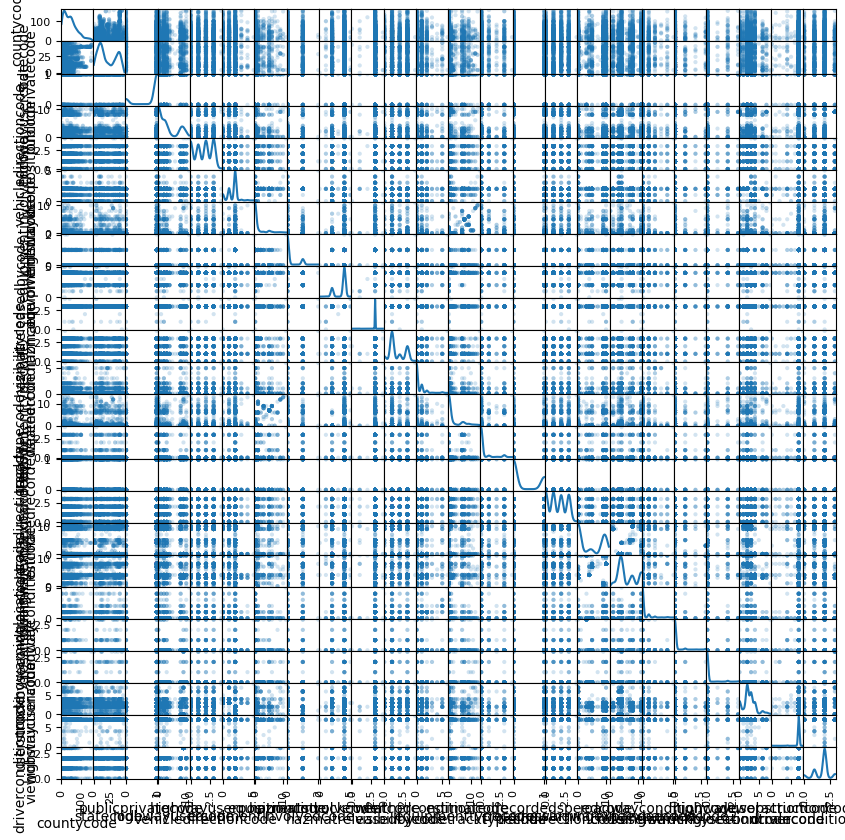

In [47]:
from pandas.plotting import scatter_matrix

# Assuming code_labels is your DataFrame with the encoded 'code' columns
scatter_matrix(Encoded_Clean_Data_Codes, alpha=0.2, figsize=(10, 10), diagonal='kde')



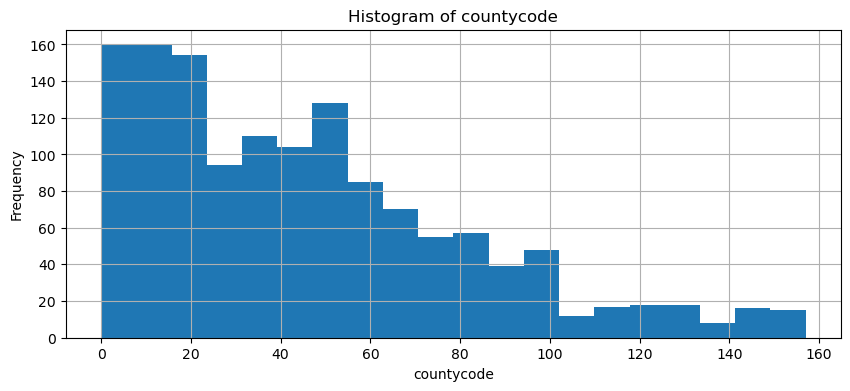

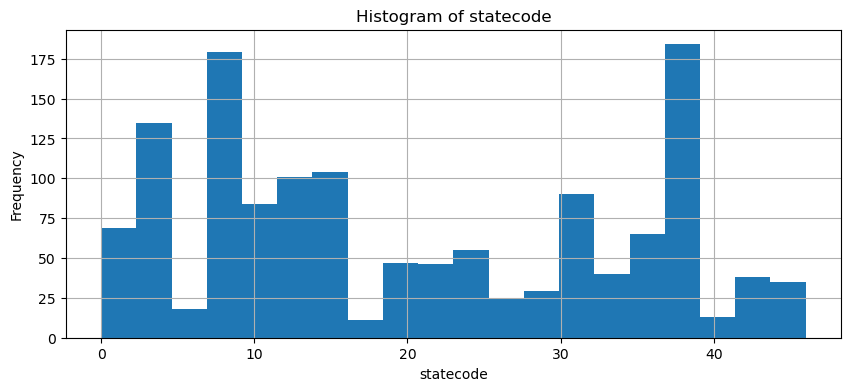

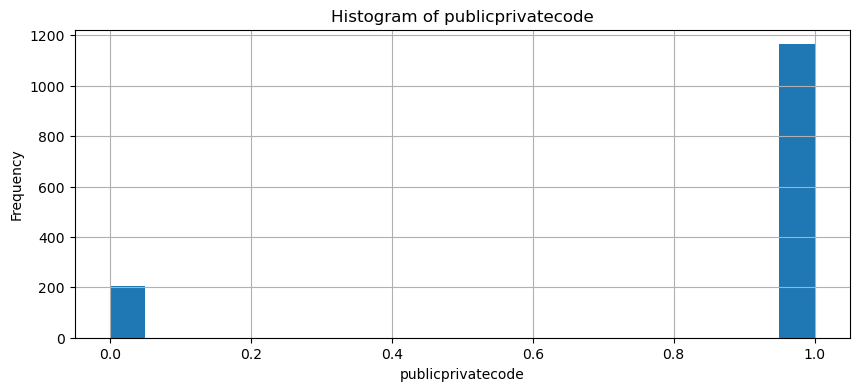

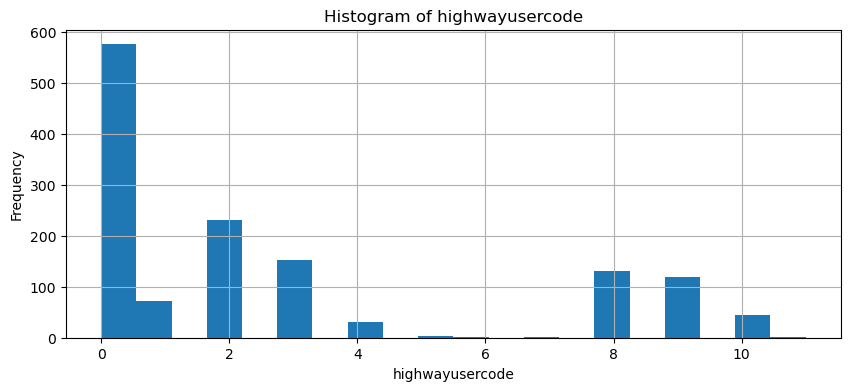

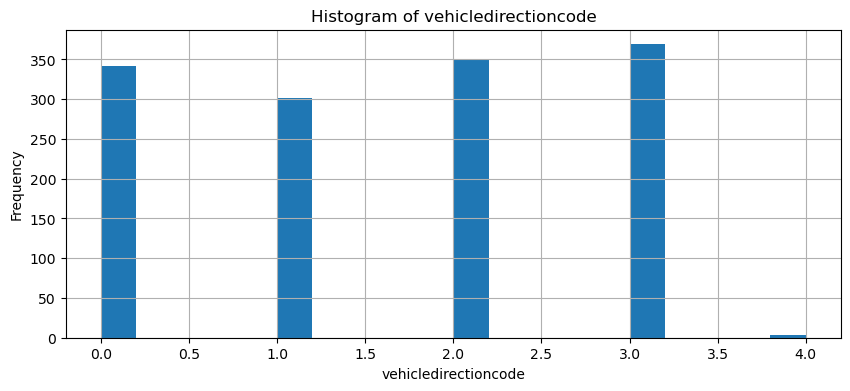

...

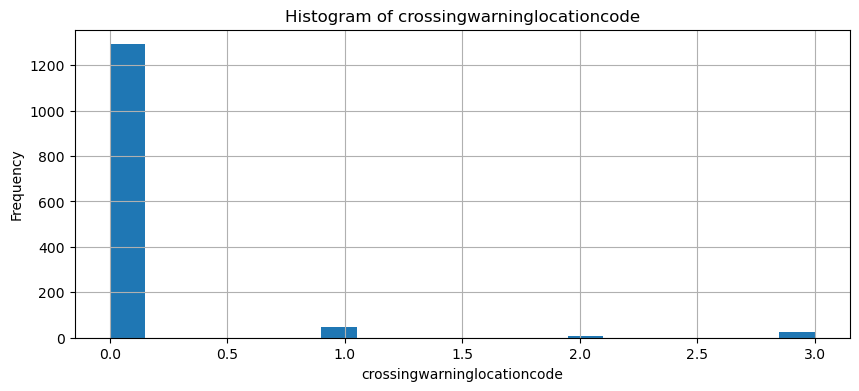

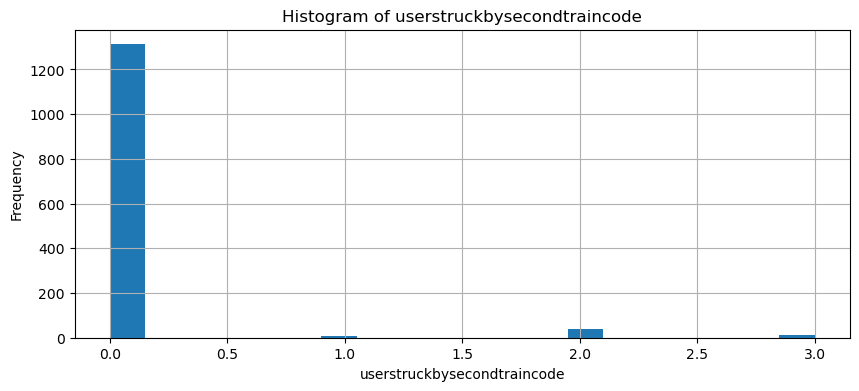

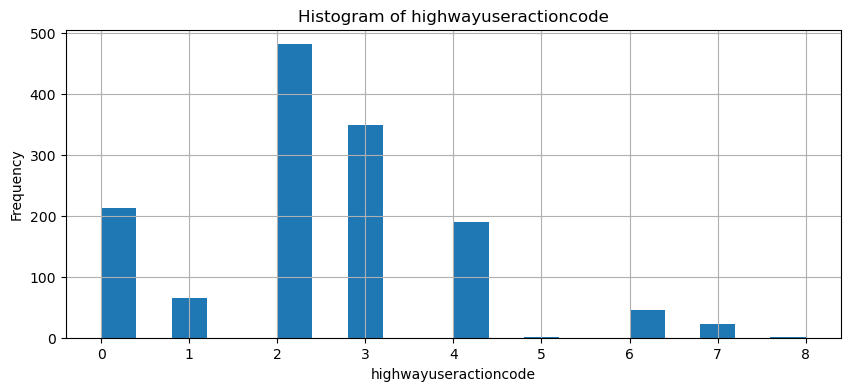

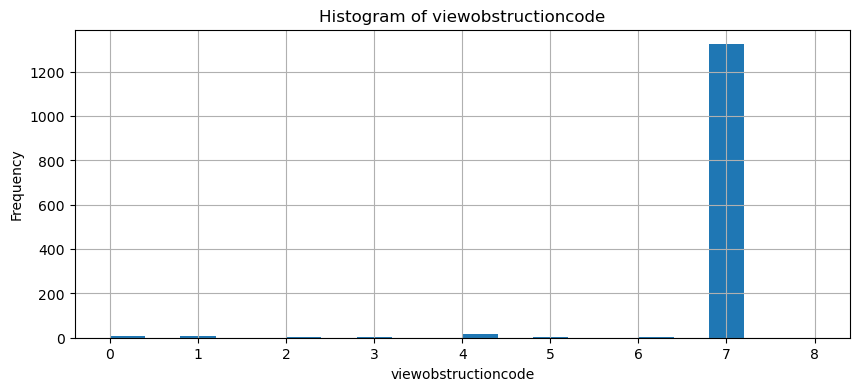

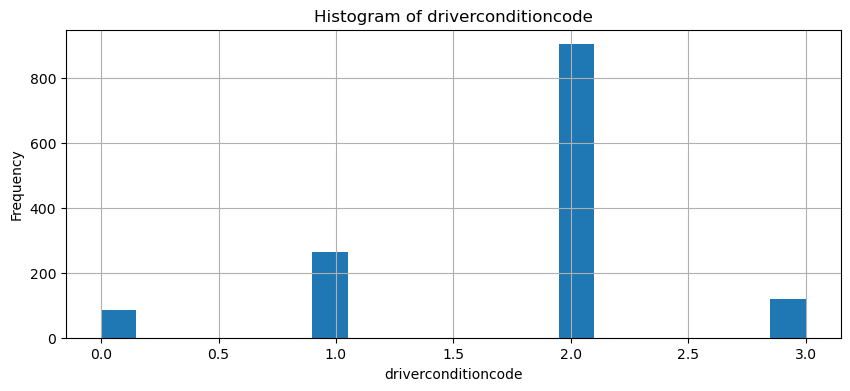

In [48]:
import matplotlib.pyplot as plt

# Plotting histograms for each column
for col in Encoded_Clean_Data_Codes.columns:
    plt.figure(figsize=(10, 4))  # Adjust the size as needed
    Encoded_Clean_Data_Codes[col].hist(bins=20)  # You can adjust the number of bins
    plt.title(f'Histogram of {col}')

    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.show()

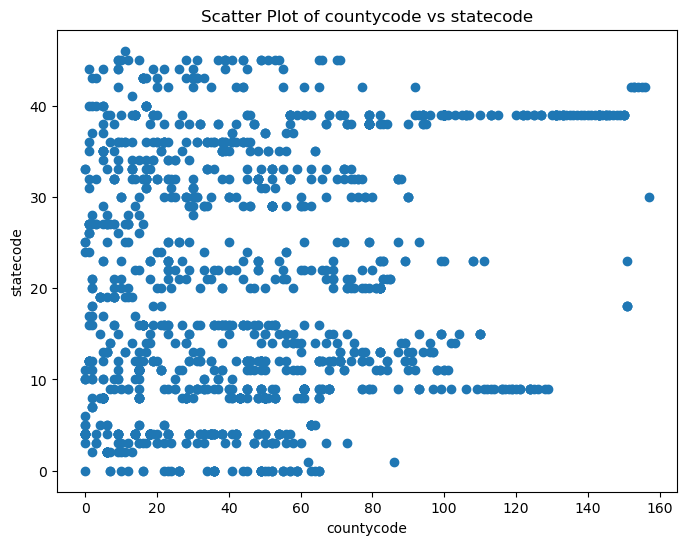

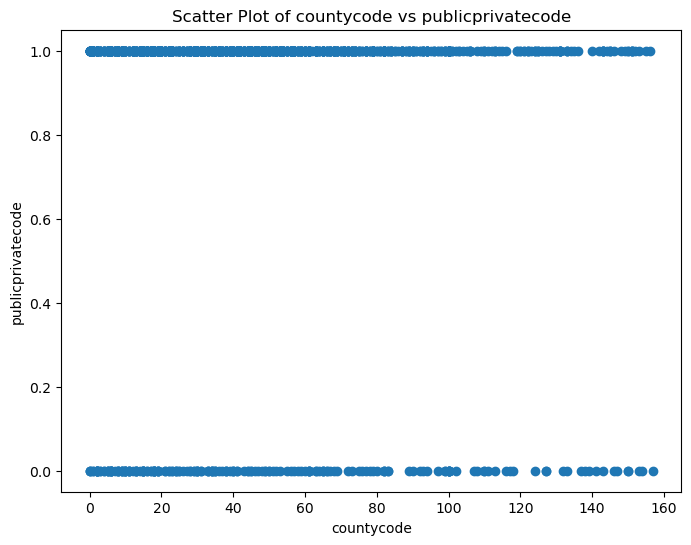

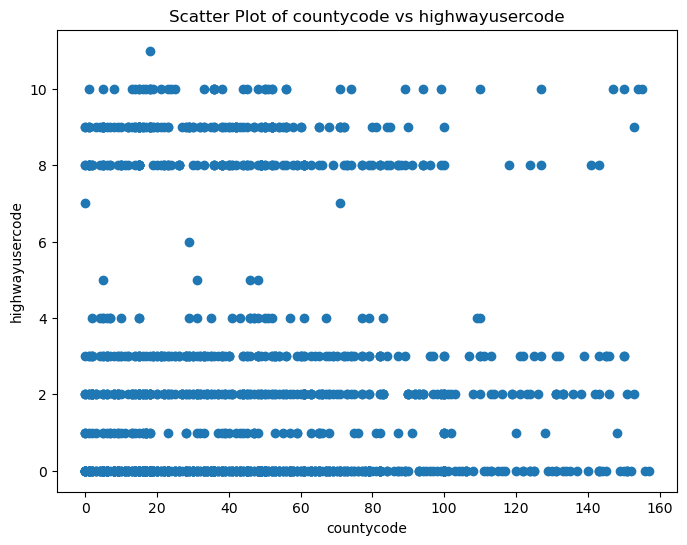

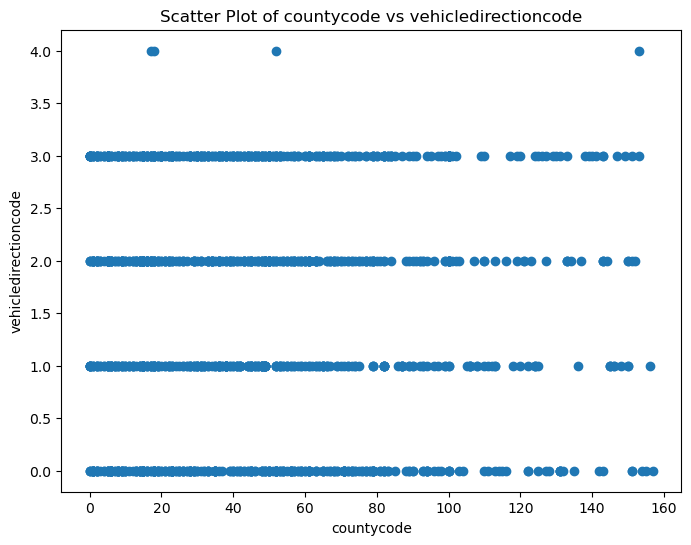

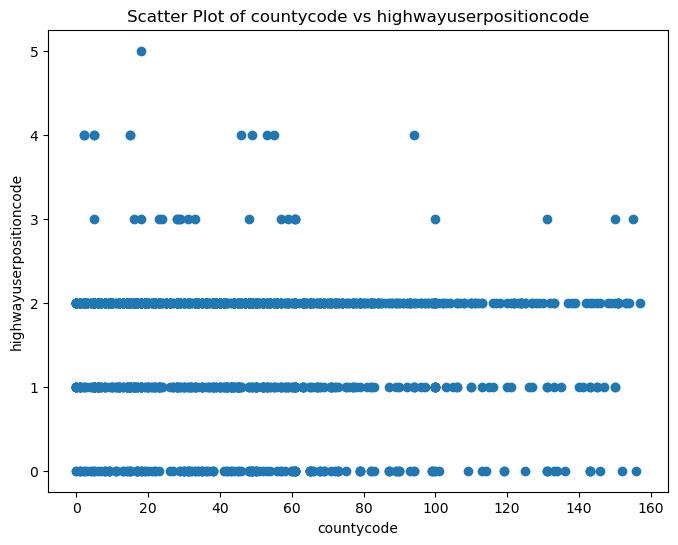

...

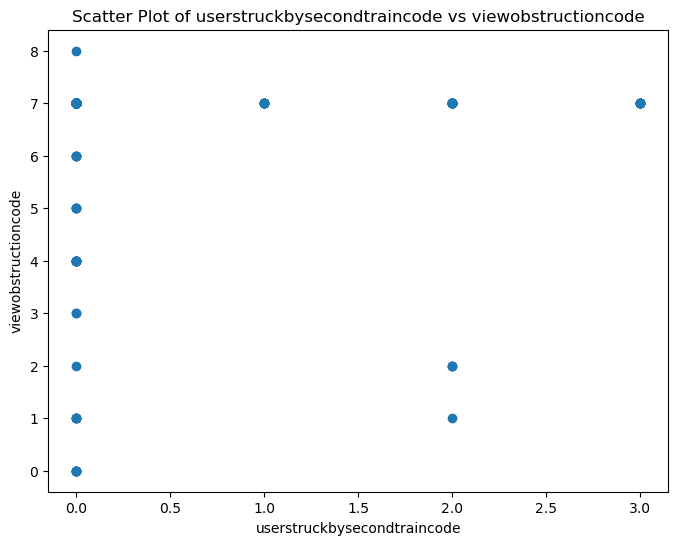

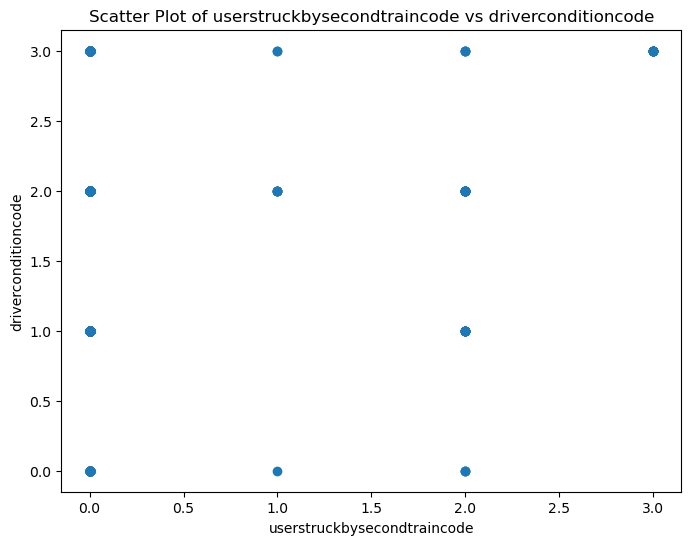

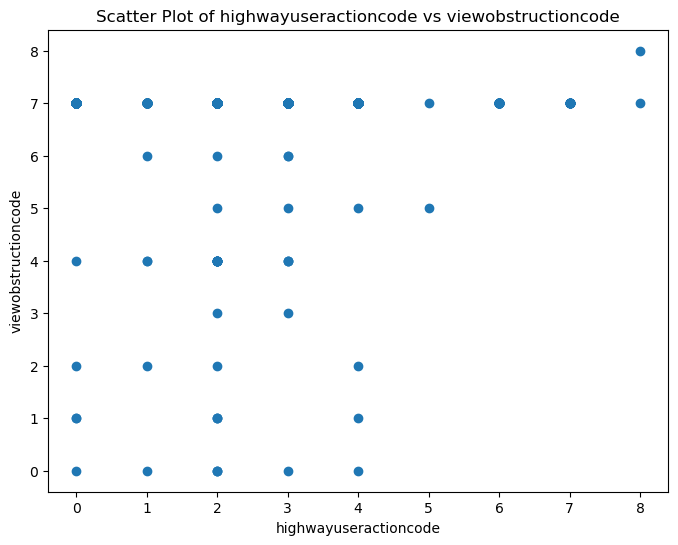

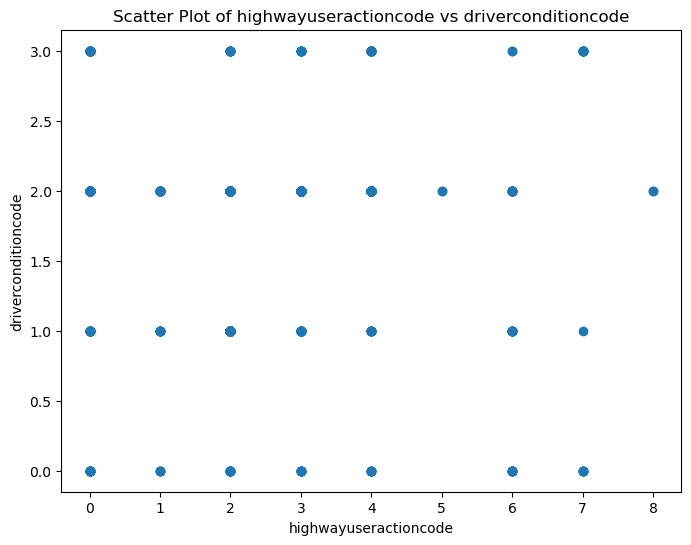

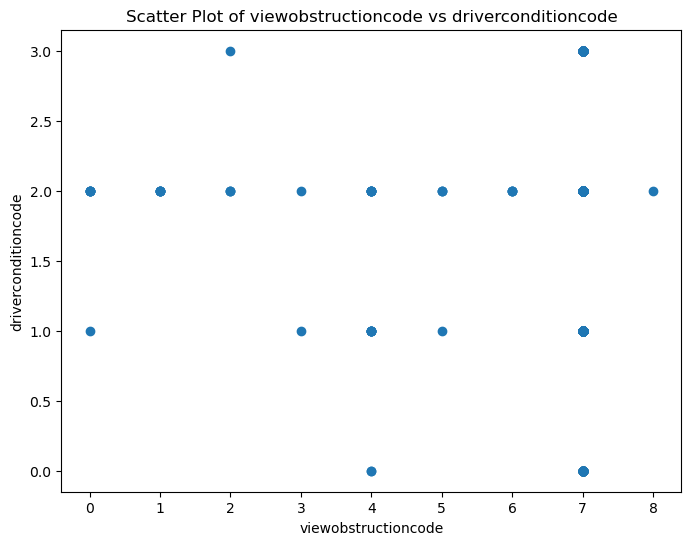

In [49]:
# Number of columns
num_cols = len(Encoded_Clean_Data_Codes.columns)

# Create scatter plots for each pair of columns
for i in range(num_cols):
    for j in range(i+1, num_cols):
        plt.figure(figsize=(8, 6))  # Adjust the size as needed
        plt.scatter(Encoded_Clean_Data_Codes.iloc[:, i], Encoded_Clean_Data_Codes.iloc[:, j])
        plt.title(f'Scatter Plot of {Encoded_Clean_Data_Codes.columns[i]} vs {Encoded_Clean_Data_Codes.columns[j]}')
        plt.xlabel(Encoded_Clean_Data_Codes.columns[i])
        plt.ylabel(Encoded_Clean_Data_Codes.columns[j])
        plt.show()

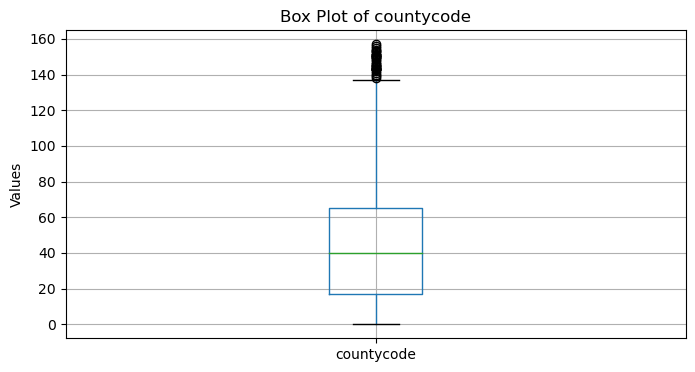

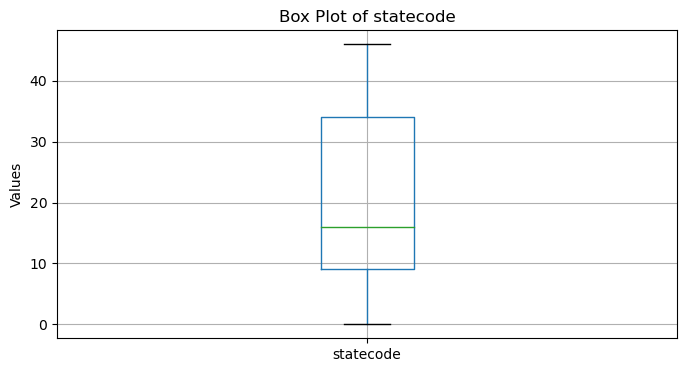

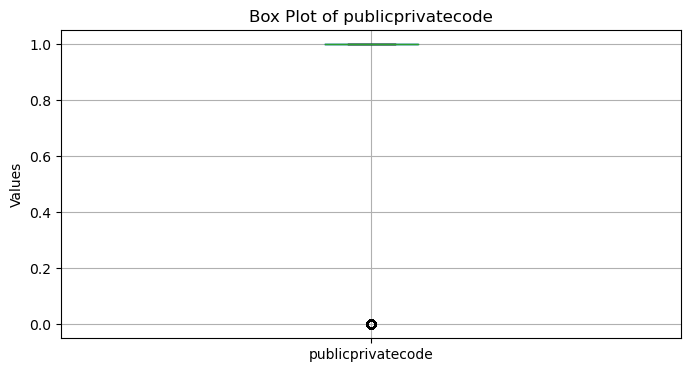

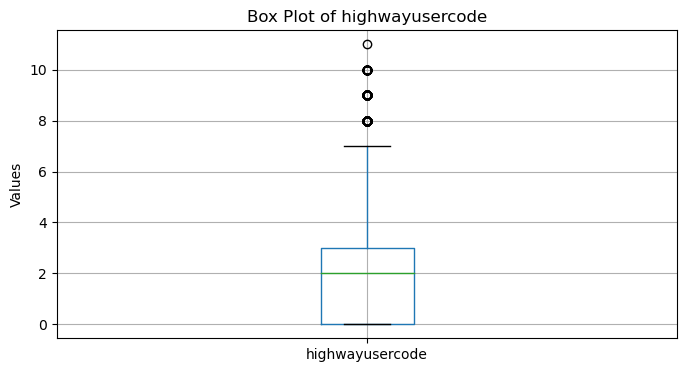

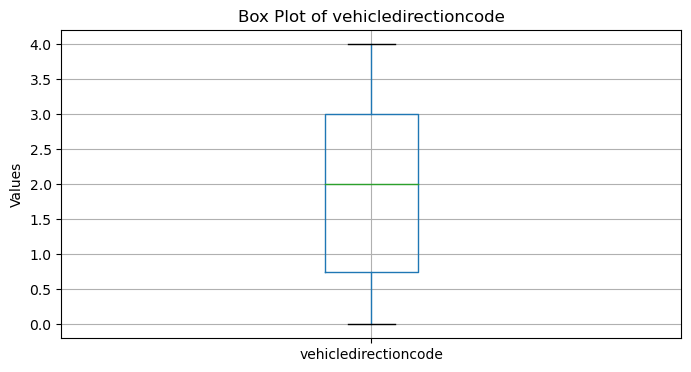

...

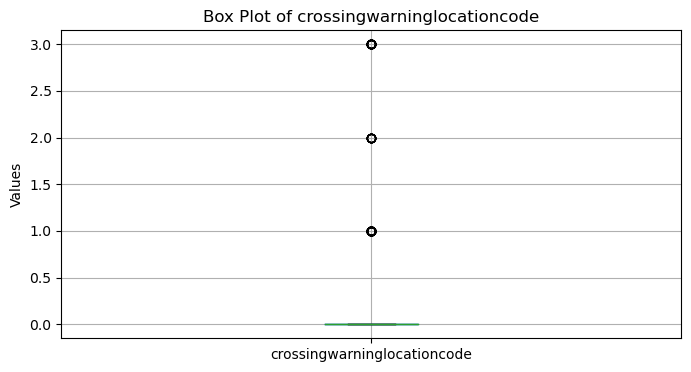

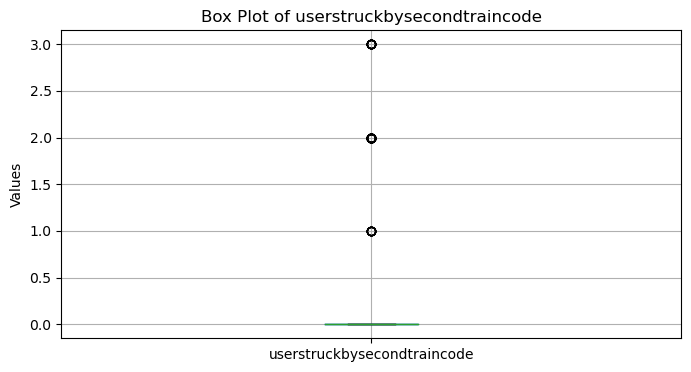

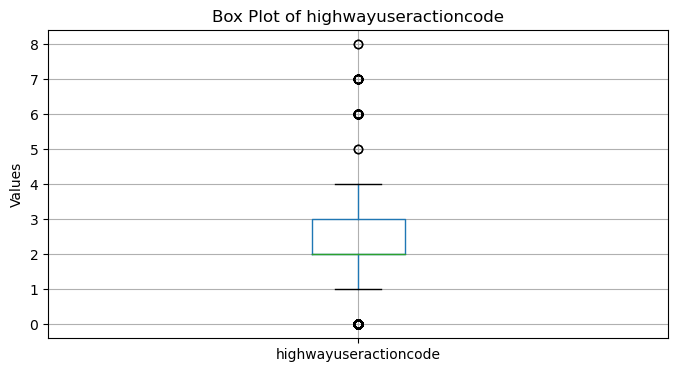

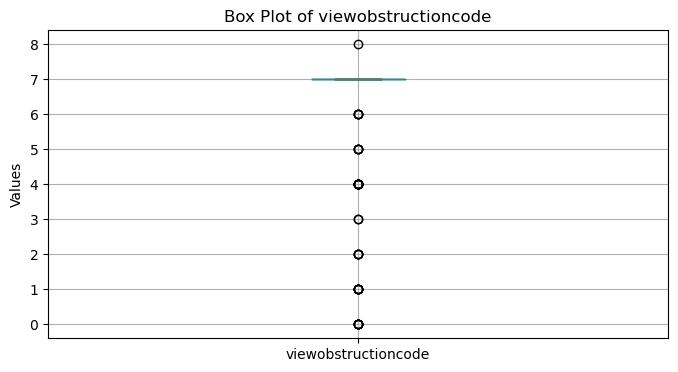

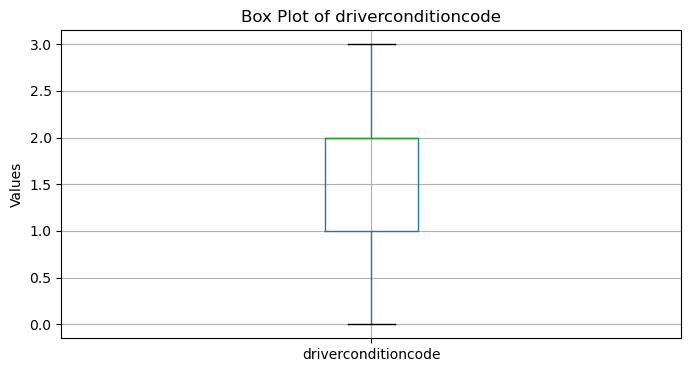

In [50]:
# Create a box plot for each column
for col in Encoded_Clean_Data_Codes.columns:
    plt.figure(figsize=(8, 4))  # Adjust the size as needed
    Encoded_Clean_Data_Codes.boxplot(column=[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel('Values')
    plt.show()

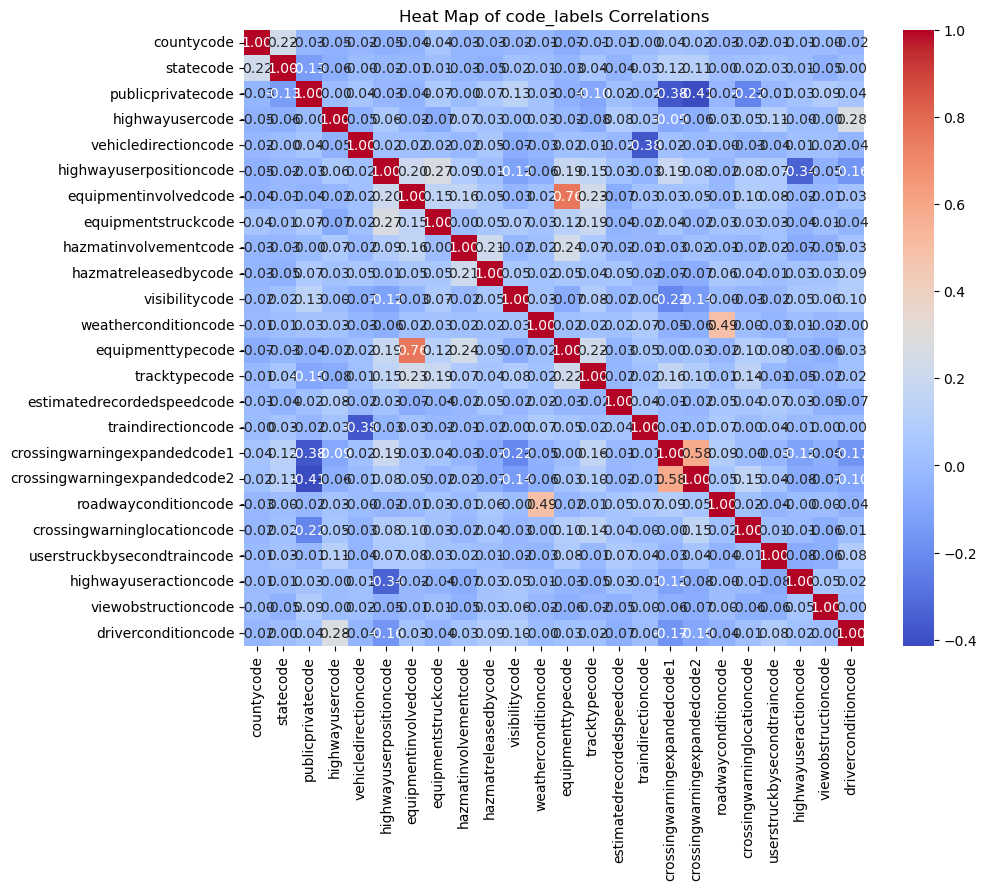

In [51]:
# Calculate the correlation matrix
corr = Encoded_Clean_Data_Codes.corr()

# Create a heatmap
plt.figure(figsize=(10, 8))  # Adjust the size as needed
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Heat Map of code_labels Correlations')
plt.show()

In [52]:
Engineered_Labels_2023 = pd.DataFrame(Clean_Data_2023['gradecrossingid'])

In [53]:
# Assume fatalities and injuries are columns in the Raw_2023_clean DataFrame
aggregated_data = Clean_Data_2023.groupby('gradecrossingid').agg({
    'totalkilledform57': 'sum',  # Sum of fatalities for each gradecrossingid
    'totalinjuredform57': 'sum',    # Sum of injuries for each gradecrossingid
    'gradecrossingid': 'size'  # Count of occurrences of each gradecrossingid
}).rename(columns={'gradecrossingid': 'id_frequency'}).reset_index()

Engineered_Labels_2023 = Engineered_Labels_2023.merge(aggregated_data, on='gradecrossingid', how='left')


In [54]:
print(Engineered_Labels_2023)

     gradecrossingid  totalkilledform57 totalinjuredform57  id_frequency
0            868284G                  0                  0             1
1            910400F                  0                  0             1
2            028672M                  0                  0             1
3            271925H                  1                  0             1
4            273145P                  0                  0             1
...              ...                ...                ...           ...
1363         870492H                  0                  1             1
1364         225588W                  0                  0             1
1365         147940X                  0                  3             1
1366         226610K                  0                  0             1
1367         807271N                  0                  0             1

[1368 rows x 4 columns]


What about vars such as am or pm , we may use hot - one encoding. 
What about vars with 'class 1,2,3' or roadway conditions: we need a system for rank or make each option a variable and define true or fasle
ie, condition: wet, dry, etc ==> is_wet: 0,1 etc


In [55]:
print(Clean_Data_2023['narrative'])

0       A SUBARU WAS STOPPED AT THE LEIRER ROAD CROSSI...
1       OPERATOR OF THE CB-9 BRUSH CUTTER SLOWED APPRO...
2       HSTOBAR101 ON MAIN 1 TRACK WAS STRUCK BY AN AU...
3       TRESPASSER WALKED UNDERNEATH SIGNAL ARMS AND W...
4       LIGHT LOCOMOTIVE TRAVELING SOUTHBOUND ON TRACK...
                              ...                        
1363    WHILE MOVING WEST UP THE SEWELL VALLEY, R20228...
1364    WHILE TRAVELING WEST ON #1 MAIN, E89507 STRUCK...
1365    L14504 STRUCK AN OCCUPIED VEHICLE AT KYLE LANE...
1366    MACHINE OPERATOR WAS MOVING TAMPER MT200709 IN...
1367    WATER TRUCK WAS STUCK IN SNOW ON CROSSING. TRA...
Name: narrative, Length: 1368, dtype: object
